# Telco Customer Churn Prediction

A telecom company loses money every time a customer cancels their subscription ("churns").
If we can predict *which* customers are likely to leave, the company can act early —
offer them a discount, better support, or a plan change — before it's too late.

**Goal:** use customer details (contract type, tenure, charges, services) to predict churn,
and compare three machine learning models to see which one does it best.

**Dataset:** IBM Telco Customer Churn — 7,043 customers, 21 columns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("data/telco_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 1. Data Cleaning

Three things need fixing before we can model anything:

1. `TotalCharges` is stored as text (some values are blank spaces), so it has to become numeric.
2. A few brand-new customers (tenure = 0) have no total charges yet — those rows get dropped,
   there are only 11 of them.
3. `customerID` is just an ID, it carries no information about churn, so it's dropped.
   The `Churn` column (Yes/No) is converted to 1/0.

In [3]:
# TotalCharges has blank strings -> coerce them to NaN so we can see how many there are
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows with missing TotalCharges:", df["TotalCharges"].isna().sum())

# These are all customers with tenure = 0 (just joined). Safe to drop such a small number.
df = df.dropna(subset=["TotalCharges"])

df = df.drop(columns=["customerID"])

# Target as 0/1
df["Churn"] = (df["Churn"] == "Yes").astype(int)

print("Cleaned shape:", df.shape)
print("Any duplicates left:", df.duplicated().sum())
df.head(3)

Rows with missing TotalCharges: 11
Cleaned shape: (7032, 20)
Any duplicates left: 22


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


## 2. Exploratory Data Analysis

First, how imbalanced is the problem? Then we look at how churn changes with
contract type, tenure, monthly charges, internet service and payment method.

Overall churn rate: 26.6%


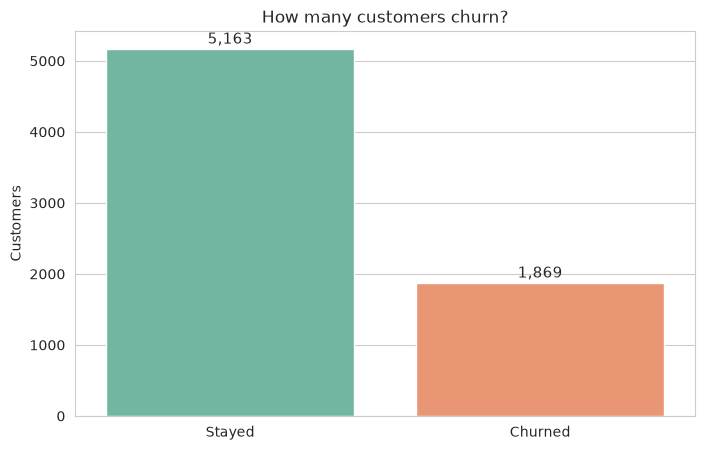

In [4]:
# Chart 1: overall churn distribution
churn_rate = df["Churn"].mean()
print(f"Overall churn rate: {churn_rate:.1%}")

ax = sns.countplot(data=df, x="Churn", hue="Churn", palette="Set2", legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Stayed", "Churned"])
ax.set_xlabel(""); ax.set_ylabel("Customers")
ax.set_title("How many customers churn?")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height() + 80),
                ha="center", fontsize=11)
plt.show()

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


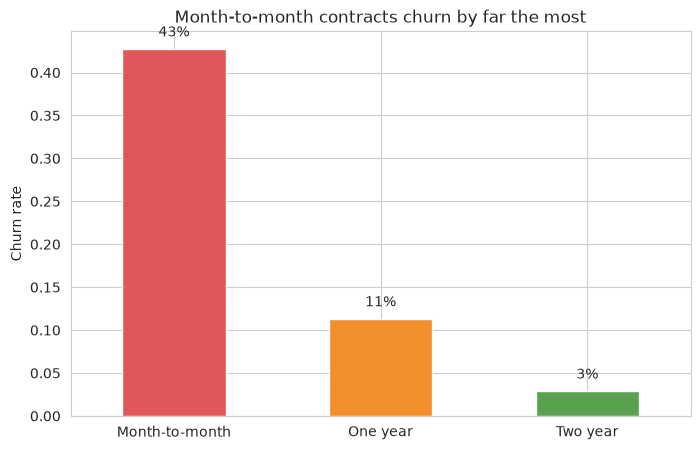

In [5]:
# Chart 2: churn rate by contract type
contract_churn = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
print(contract_churn.round(3))

ax = contract_churn.plot(kind="bar", color=["#e15759", "#f28e2b", "#59a14f"])
ax.set_ylabel("Churn rate"); ax.set_xlabel("")
ax.set_title("Month-to-month contracts churn by far the most")
plt.xticks(rotation=0)
for i, v in enumerate(contract_churn):
    ax.annotate(f"{v:.0%}", (i, v + 0.015), ha="center")
plt.show()

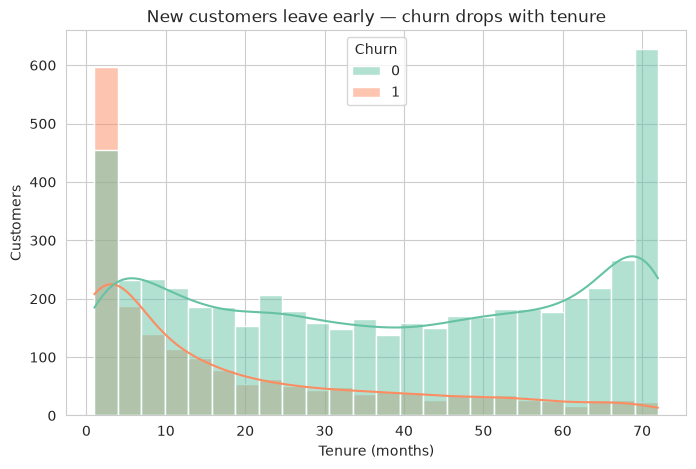

Median tenure, churned: 10.0
Median tenure, stayed : 38.0


In [6]:
# Chart 3: tenure distribution, split by churn
ax = sns.histplot(data=df, x="tenure", hue="Churn", bins=24, kde=True, palette="Set2")
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Customers")
ax.set_title("New customers leave early — churn drops with tenure")
plt.show()

print("Median tenure, churned:", df.loc[df.Churn == 1, "tenure"].median())
print("Median tenure, stayed :", df.loc[df.Churn == 0, "tenure"].median())

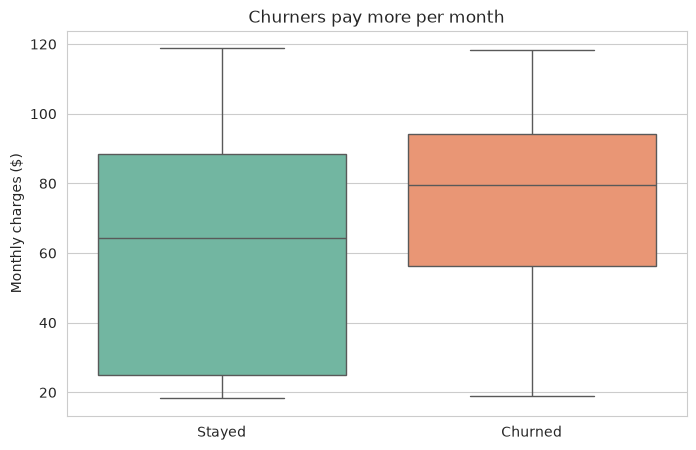

In [7]:
# Chart 4: monthly charges, split by churn
ax = sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", palette="Set2", legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Stayed", "Churned"])
ax.set_xlabel(""); ax.set_ylabel("Monthly charges ($)")
ax.set_title("Churners pay more per month")
plt.show()

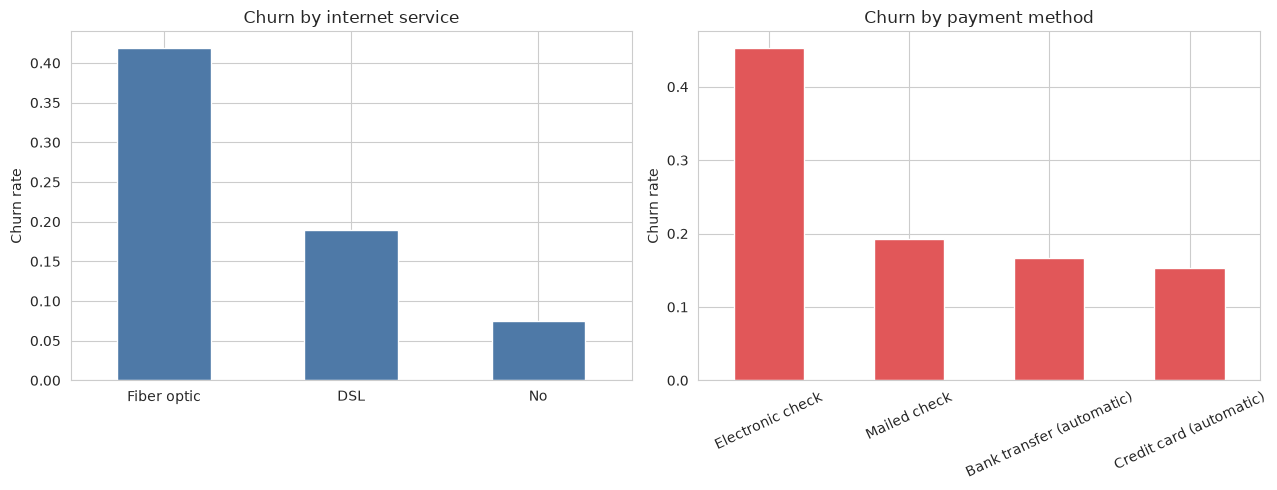

Churn rate by internet service:
 InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn, dtype: float64

Churn rate by payment method:
 PaymentMethod
Electronic check             0.453
Mailed check                 0.192
Bank transfer (automatic)    0.167
Credit card (automatic)      0.153
Name: Churn, dtype: float64


In [8]:
# Chart 5: churn rate by internet service and by payment method
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

internet_churn = df.groupby("InternetService")["Churn"].mean().sort_values(ascending=False)
internet_churn.plot(kind="bar", ax=axes[0], color="#4e79a7")
axes[0].set_title("Churn by internet service"); axes[0].set_ylabel("Churn rate"); axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

payment_churn = df.groupby("PaymentMethod")["Churn"].mean().sort_values(ascending=False)
payment_churn.plot(kind="bar", ax=axes[1], color="#e15759")
axes[1].set_title("Churn by payment method"); axes[1].set_ylabel("Churn rate"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout(); plt.show()
print("Churn rate by internet service:\n", internet_churn.round(3))
print("\nChurn rate by payment method:\n", payment_churn.round(3))

### What the EDA tells us

- **Contract type is the biggest signal.** Month-to-month customers churn at roughly 42%,
  versus ~11% on one-year and ~3% on two-year contracts.
- **Fibre-optic customers churn the most** (~42%) — they also pay the highest monthly bills,
  so price may be part of the story.
- **Electronic-check payers churn far more** (~45%) than customers on automatic payments.
- **Churn is a new-customer problem:** the median churner leaves after ~10 months,
  while loyal customers stay for years.
- **Higher monthly charges → higher churn**, which matches the fibre-optic pattern.

## 3. Feature Engineering

New features built from the raw columns:

- **`tenure_group`** — tenure bucketed into `0-12`, `13-24`, `25-48`, `49-72` months,
  since churn risk changes a lot over a customer's lifetime.
- **`num_addons`** — how many of the six add-on services (online security, backup,
  device protection, tech support, streaming TV/movies) the customer subscribes to.
  More add-ons should mean a "stickier" customer.
- **`avg_charge_per_month`** — total charges divided by tenure, a sanity check on billing.

After that, every categorical column is one-hot encoded so the models can use it.

In [9]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]

df["num_addons"] = (df[addons] == "Yes").sum(axis=1)
df["tenure_group"] = pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"])
df["avg_charge_per_month"] = df["TotalCharges"] / df["tenure"].clip(lower=1)

print("Churn rate by number of add-ons:")
print(df.groupby("num_addons")["Churn"].mean().round(3))
df[["tenure", "tenure_group", "num_addons", "avg_charge_per_month"]].head()

Churn rate by number of add-ons:
num_addons
0    0.215
1    0.458
2    0.358
3    0.274
4    0.224
5    0.125
6    0.053
Name: Churn, dtype: float64


,tenure,tenure_group,num_addons,avg_charge_per_month
0,1,0-12,1,29.850000
1,34,25-48,2,55.573529
2,2,0-12,2,54.075000
3,45,25-48,3,40.905556
4,2,0-12,0,75.825000


In [10]:
# One-hot encode all categorical columns
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)
y = df["Churn"]
print("Feature matrix:", X.shape)
X.head(3)

Feature matrix: (7032, 35)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,num_addons,avg_charge_per_month,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,...,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_13-24,tenure_group_25-48,tenure_group_49-72
0,0,1,29.85,29.85,1,29.850000,False,True,False,False,...,False,False,False,True,False,True,False,False,False,False
1,0,34,56.95,1889.50,2,55.573529,True,False,False,True,...,False,True,False,False,False,False,True,False,True,False
2,0,2,53.85,108.15,2,54.075000,True,False,False,True,...,False,False,False,True,False,False,True,False,False,False


## 4. Train / Test Split and Models

The data is split 80/20 with **stratification**, so the train and test sets keep the
same churn ratio as the full data. Logistic Regression gets scaled features (it is
sensitive to feature scales); the tree models don't need scaling.

Three models are compared:

| Model | Why include it |
|---|---|
| Logistic Regression | Simple, interpretable baseline |
| Random Forest | Handles non-linear patterns, robust |
| Gradient Boosting | Usually the strongest of the three on tabular data |

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

results_df = pd.DataFrame(results).T.round(4)
results_df

Train: (5625, 35) | Test: (1407, 35)


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.7939,0.6355,0.5267,0.5760,0.8348
Random Forest,0.7889,0.6262,0.5107,0.5626,0.8210
Gradient Boosting,0.7967,0.6457,0.5214,0.5769,0.8400


## 5. Evaluating the Best Model

Accuracy alone is misleading on imbalanced data, so the models are ranked by **ROC-AUC**
(how well they separate churners from loyal customers across all thresholds).
For churn, **recall matters too** — missing a customer who is about to leave costs more
than a false alarm.

Best model by ROC-AUC: Gradient Boosting


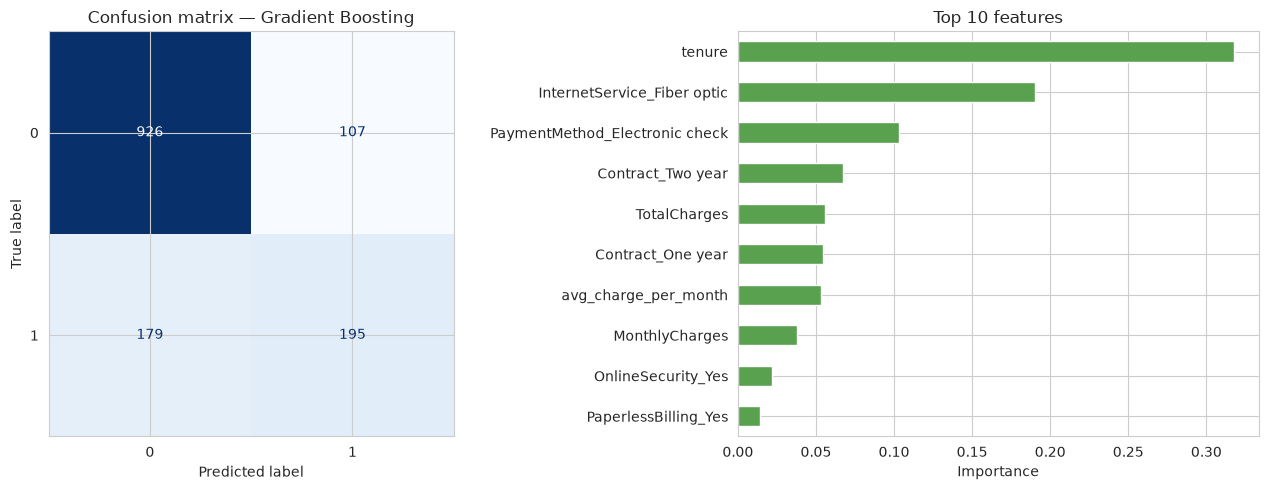

Top 3 features: ['tenure', 'InternetService_Fiber optic', 'PaymentMethod_Electronic check']


In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_name = results_df["ROC-AUC"].idxmax()
best_model = models[best_name]
print("Best model by ROC-AUC:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix of the best model
disp = ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, ax=axes[0],
                                             colorbar=False, cmap="Blues")
disp.ax_.set_title(f"Confusion matrix — {best_name}")

# Feature importances (works for both tree models; for LR use coefficients)
if best_name == "Logistic Regression":
    importances = pd.Series(best_model.named_steps["model"].coef_[0], index=X.columns).abs()
else:
    importances = pd.Series(best_model.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(10)

top_features.sort_values().plot(kind="barh", ax=axes[1], color="#59a14f")
axes[1].set_title("Top 10 features"); axes[1].set_xlabel("Importance")

plt.tight_layout(); plt.show()
print("Top 3 features:", list(top_features.head(3).index))

## 6. Conclusion

**Results:** Gradient Boosting came out best, with a ROC-AUC of 0.840, accuracy of 79.7% and
an F1 score of 0.577 — slightly ahead of Logistic Regression (0.835 ROC-AUC); Random Forest
was close behind on accuracy but weaker on ROC-AUC (0.821). All numbers are in the results
table above and in `metrics.json`. The best model's top features — tenure, fibre-optic
service and electronic-check payment — match exactly what the EDA pointed to.

**Business takeaways:**

1. **Focus retention offers on month-to-month customers in their first year** — that is where
   almost all the churn is. A small discount to move them onto a one-year contract pays for itself.
2. **Investigate the fibre-optic experience.** Fibre customers pay the most and leave the most;
   either the price or the service quality is not matching expectations.
3. **Nudge electronic-check payers toward auto-pay.** Automatic payment methods churn at less
   than half the rate — even a small sign-up incentive could help.
4. **Use `num_addons` as an early-warning signal:** customers with zero add-ons and short tenure
   are the highest-risk segment and the cheapest to target.

**Next steps if this were a real project:** tune the decision threshold for higher recall,
try hyperparameter tuning / XGBoost, and add SHAP explanations so the retention team can see
*why* each customer was flagged.

In [13]:
# Save the key numbers so they can be quoted in the README / a resume
import json

contract = df.groupby("Contract")["Churn"].mean()
metrics_out = {
    "dataset_rows": int(len(df)),
    "churn_rate": round(float(df["Churn"].mean()), 4),
    "models": {
        name: {
            "accuracy": round(float(r["Accuracy"]), 4),
            "precision": round(float(r["Precision"]), 4),
            "recall": round(float(r["Recall"]), 4),
            "f1": round(float(r["F1 Score"]), 4),
            "roc_auc": round(float(r["ROC-AUC"]), 4),
        } for name, r in results.items()
    },
    "best_model": best_name,
    "top_features": list(top_features.head(3).index),
    "eda_findings": [
        f"Month-to-month customers churn at {contract['Month-to-month']:.0%}, vs "
        f"{contract['Two year']:.0%} for two-year contracts",
        f"Fibre-optic users churn at "
        f"{df.groupby('InternetService')['Churn'].mean()['Fiber optic']:.0%}, the highest of any internet service",
        f"Electronic-check payers churn at "
        f"{df.groupby('PaymentMethod')['Churn'].mean()['Electronic check']:.0%}, vs under 20% for automatic payment methods",
    ],
}
with open("metrics.json", "w") as f:
    json.dump(metrics_out, f, indent=2)
print(json.dumps(metrics_out, indent=2))

{
  "dataset_rows": 7032,
  "churn_rate": 0.2658,
  "models": {
    "Logistic Regression": {
      "accuracy": 0.7939,
      "precision": 0.6355,
      "recall": 0.5267,
      "f1": 0.576,
      "roc_auc": 0.8348
    },
    "Random Forest": {
      "accuracy": 0.7889,
      "precision": 0.6262,
      "recall": 0.5107,
      "f1": 0.5626,
      "roc_auc": 0.821
    },
    "Gradient Boosting": {
      "accuracy": 0.7967,
      "precision": 0.6457,
      "recall": 0.5214,
      "f1": 0.5769,
      "roc_auc": 0.84
    }
  },
  "best_model": "Gradient Boosting",
  "top_features": [
    "tenure",
    "InternetService_Fiber optic",
    "PaymentMethod_Electronic check"
  ],
  "eda_findings": [
    "Month-to-month customers churn at 43%, vs 3% for two-year contracts",
    "Fibre-optic users churn at 42%, the highest of any internet service",
    "Electronic-check payers churn at 45%, vs under 20% for automatic payment methods"
  ]
}
